## 02. Model Creation and Data Splitting/Vectorization

- Model Creation notebook for baseline model: Naive Bayes and unparametered Random Forest

In [1]:
from pathlib import Path
import sys

sys.path.append(str(Path.cwd().parents[0]))
from src.tuning import visualize_metrics, show_metrics
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/processed/sms_cleaned_data.csv')
df.head(10)

,date,text,carrier,target,punctuation_count,text_count,has_url,has_money_mention,has_phone_in_text,exclamation_count,uppercase_ratio,word_count,year,month
0,2026-07-01 09:13:32.668,login free spin marami nakakuha moneytoken sus...,Unknown,2,8,120,1.0,1.0,0.0,2.0,0.075000,9,2026,July
1,2026-04-23 01:01:22.884,condo across ateneo torre lorenzo studio units...,Smart,2,4,149,0.0,0.0,0.0,0.0,0.046980,15,2026,April
2,2026-03-27 06:23:44.260,papalduhin kita moneytoken ngayon basta bahala...,Smart,1,6,167,0.0,1.0,0.0,0.0,0.071856,22,2026,March
3,2026-02-17 10:25:35.838,boss panalunin kita pinata win moneytoken haba...,Smart,1,11,186,0.0,1.0,0.0,0.0,0.016129,20,2026,February
4,2026-01-19 16:13:33.766,nagsisimula saya panalo moneytoken free moneyt...,Smart,2,5,108,1.0,1.0,0.0,1.0,0.111111,11,2026,January
5,2025-11-15 10:25:41.961,okay makipag deal sayo cash ipapanalo kita mon...,Smart,1,10,195,0.0,1.0,0.0,0.0,0.020513,25,2025,November
6,2025-11-14 02:22:40.382,good day ms ivie multi banking personal cash l...,Smart,2,8,229,0.0,1.0,0.0,0.0,0.052402,27,2025,November
7,2025-08-27 09:28:23.142,fex parcel p iisddcddtba reach please contact ...,Smart,1,5,109,0.0,0.0,1.0,0.0,0.119266,10,2025,August
8,2025-08-19 08:57:21.957,smart reminds reward points expire today pleas...,Unknown,1,11,114,1.0,0.0,0.0,0.0,0.043860,11,2025,August
9,2025-08-12 22:16:30.612,landbank iaccess account deducted moneytoken a...,Unknown,1,12,178,1.0,1.0,0.0,0.0,0.095506,11,2025,August


## Multinomial and Complement Naive Bayes

In [2]:
# used for deduplication in splitting criteria
df['dedup_group_id'] = pd.factorize(df['text'])[0]

binary_cols = ['has_url', 'has_money_mention', 'has_phone_in_text']
numericals = ['exclamation_count', 'text_count', 'word_count',
              'punctuation_count', 'uppercase_ratio']

x = df['text']
y = df['target']

# splitting and vectorization
vectorizer = TfidfVectorizer(ngram_range=(1, 3), min_df=2, max_df=0.9, sublinear_tf=True)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
scaler = MinMaxScaler(clip=True)
train_idx, test_idx = next(sgkf.split(x, y, groups=df['dedup_group_id']))

train_data = df.iloc[train_idx].reset_index(drop=True)
test_data = df.iloc[test_idx].reset_index(drop=True)

X_train = vectorizer.fit_transform(train_data['text'])
X_test = vectorizer.transform(test_data['text'])
y_train = train_data['target']
y_test = test_data['target']

num_train = scaler.fit_transform(train_data[numericals])
num_test  = scaler.transform(test_data[numericals])

bin_train = train_data[binary_cols].to_numpy(dtype=float)
bin_test  = test_data[binary_cols].to_numpy(dtype=float)

X_train = hstack([X_train, csr_matrix(bin_train), csr_matrix(num_train)]).tocsr()
X_test  = hstack([X_test,  csr_matrix(bin_test),  csr_matrix(num_test)]).tocsr()

# init both naive bayes model
mnb = MultinomialNB(alpha=0.5)
cnb = ComplementNB(alpha=0.5)

mnb.fit(X_train, y_train)
cnb.fit(X_train, y_train)

ypred_mnb = mnb.predict(X_test)
ypred_cnb = cnb.predict(X_test)

yprob_mnb = mnb.predict_proba(X_test)
yprob_cnb = cnb.predict_proba(X_test)

print(f"Training Data Size: {len(train_data)} | Test Data Size: {len(test_data)}")

Training Data Size: 817 | Test Data Size: 204


In [3]:
show_metrics(y_test, ypred_mnb, yprob_mnb)

Accuracy and ROC AUC Score
Accuracy Score: 71.569%
ROC AUC Score: 89.596%
              precision    recall  f1-score   support

           0       0.83      0.54      0.65        54
           1       0.66      0.82      0.73        82
           2       0.74      0.74      0.74        68

    accuracy                           0.72       204
   macro avg       0.74      0.70      0.71       204
weighted avg       0.73      0.72      0.71       204



In [4]:
show_metrics(y_test, ypred_cnb, yprob_cnb)

Accuracy and ROC AUC Score
Accuracy Score: 73.529%
ROC AUC Score: 89.939%
              precision    recall  f1-score   support

           0       0.75      0.67      0.71        54
           1       0.74      0.78      0.76        82
           2       0.72      0.74      0.73        68

    accuracy                           0.74       204
   macro avg       0.74      0.73      0.73       204
weighted avg       0.74      0.74      0.73       204



## Visualizing Classifcation Metrics in MNB and CNB

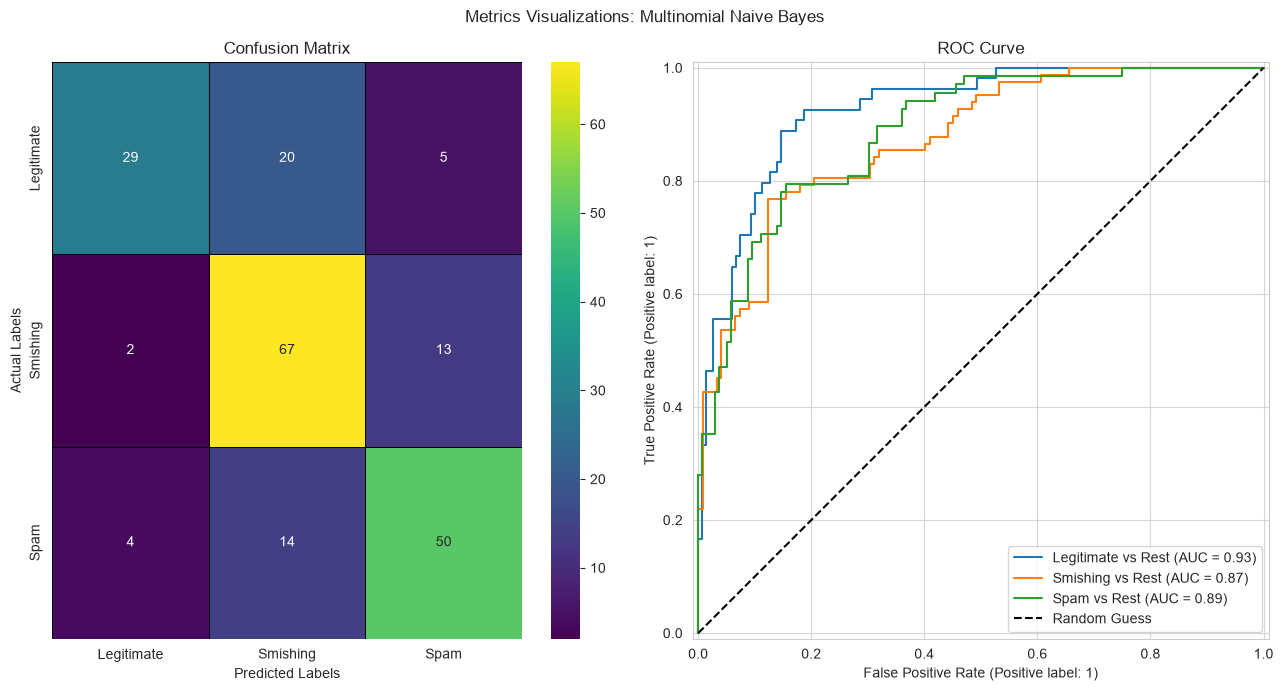

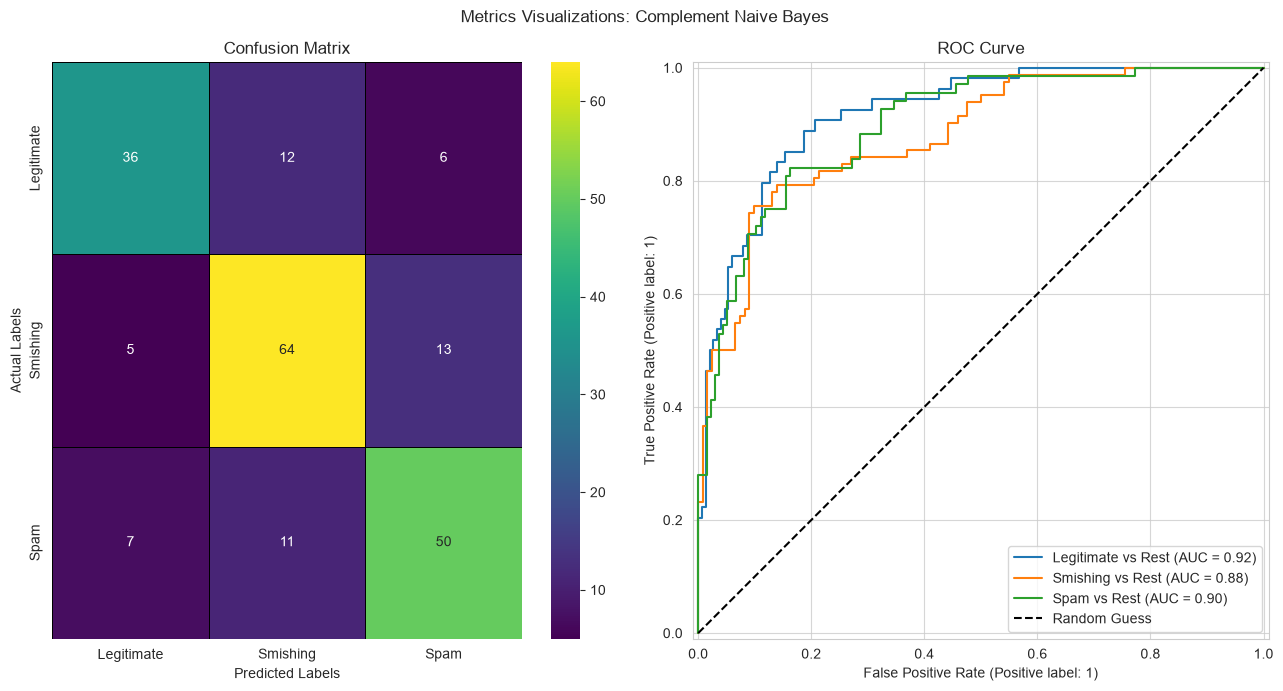

In [5]:
cm_mnb = confusion_matrix(y_test, ypred_mnb)
cm_cnb = confusion_matrix(y_test, ypred_cnb)

visualize_metrics(mnb, cm_mnb, X_test, y_test, 'Multinomial Naive Bayes',
                  labels=['Legitimate', 'Smishing', 'Spam'])

visualize_metrics(cnb, cm_cnb, X_test, y_test, 'Complement Naive Bayes',
                  ['Legitimate', 'Smishing', 'Spam'])

## Random Forest Classifier

In [6]:
rf = RandomForestClassifier(random_state=42, n_estimators=100, criterion='log_loss')

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)
cm_rf = confusion_matrix(y_test, rf_pred)

show_metrics(y_test, rf_pred, rf_prob)

Accuracy and ROC AUC Score
Accuracy Score: 78.922%
ROC AUC Score: 90.614%
              precision    recall  f1-score   support

           0       0.74      0.80      0.77        54
           1       0.79      0.89      0.84        82
           2       0.83      0.66      0.74        68

    accuracy                           0.79       204
   macro avg       0.79      0.78      0.78       204
weighted avg       0.79      0.79      0.79       204



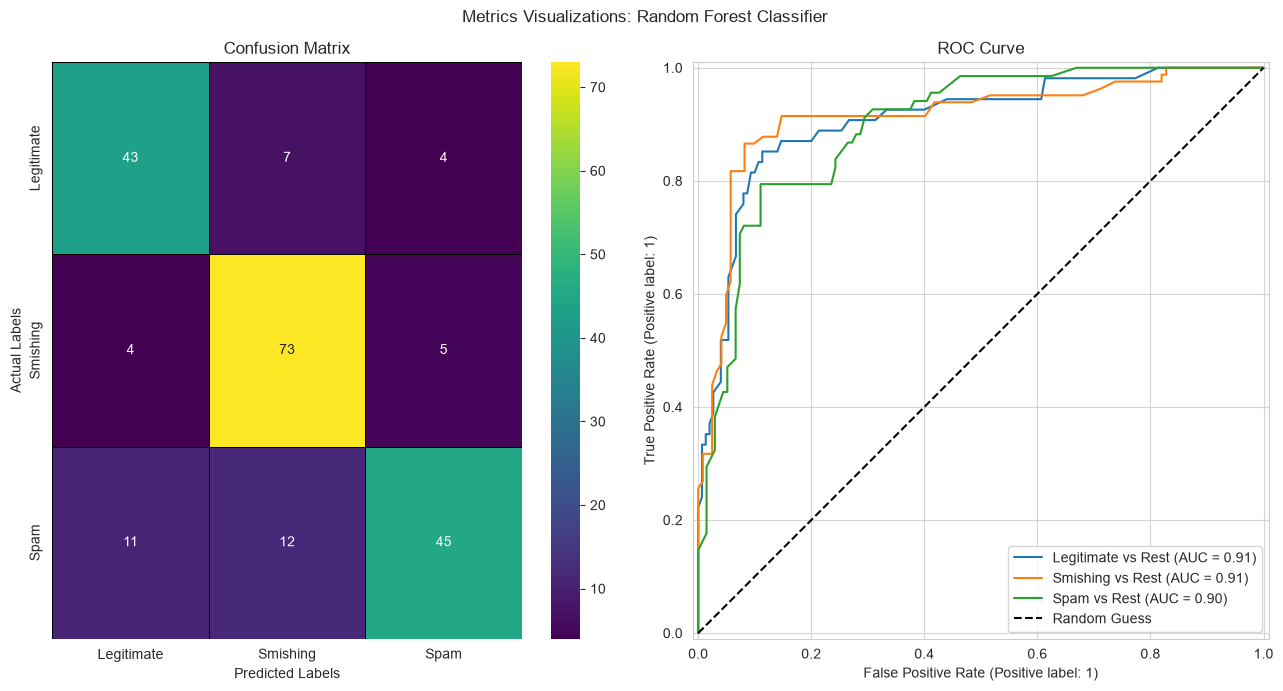

In [7]:
visualize_metrics(rf, cm_rf, X_test, y_test, "Random Forest Classifier",labels=['Legitimate', 'Smishing', 'Spam'])